# Import Libraries

In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Load Data

In [104]:
df = pd.read_csv("/kaggle/input/datasets/organizations/mlg-ulb/creditcardfraud/creditcard.csv")

In [75]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# Data Overview

In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [77]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [78]:
# distribution of leit transaction & fraudulent transaction (Balance)
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [106]:
legit = df[df.Class == 0]
fraud = df[df.Class == 1]

In [107]:
print(legit.shape)
print(fraud.shape)

(284315, 31)
(492, 31)


In [108]:
legit.Amount.describe()

count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

In [109]:
fraud.Amount.describe()

count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

In [110]:
# Compare the values for both transaction 
df.groupby('Class').mean()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
Class,,,,,,,,,,,,,,,,,,,,,
0,94838.202258,0.008258,-0.006271,0.012171,-0.007860,0.005453,0.002419,0.009637,-0.000987,0.004467,...,-0.000644,-0.001235,-0.000024,0.000070,0.000182,-0.000072,-0.000089,-0.000295,-0.000131,88.291022
1,80746.806911,-4.771948,3.623778,-7.033281,4.542029,-3.151225,-1.397737,-5.568731,0.570636,-2.581123,...,0.372319,0.713588,0.014049,-0.040308,-0.105130,0.041449,0.051648,0.170575,0.075667,122.211321


# EDA (Exploratory Data Analysis)

Class
0    284315
1       492
Name: count, dtype: int64


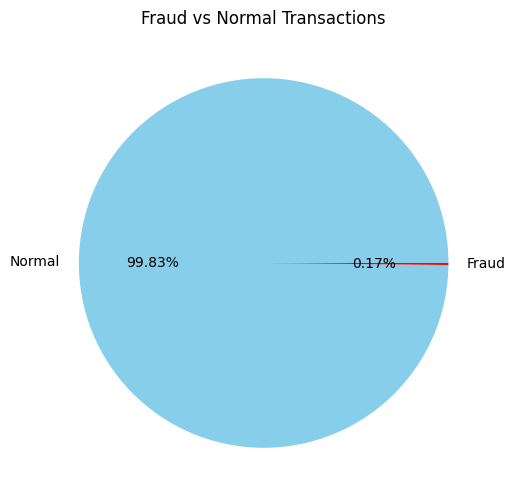

In [84]:
# Count Fraud / Non-Fraud
fraud_counts = df['Class'].value_counts()

print(fraud_counts)

plt.figure(figsize=(6,6))
plt.pie(
    fraud_counts,
    labels=['Normal', 'Fraud'],
    autopct='%1.2f%%',
    colors=['skyblue', 'red']
)

plt.title("Fraud vs Normal Transactions")
plt.show()

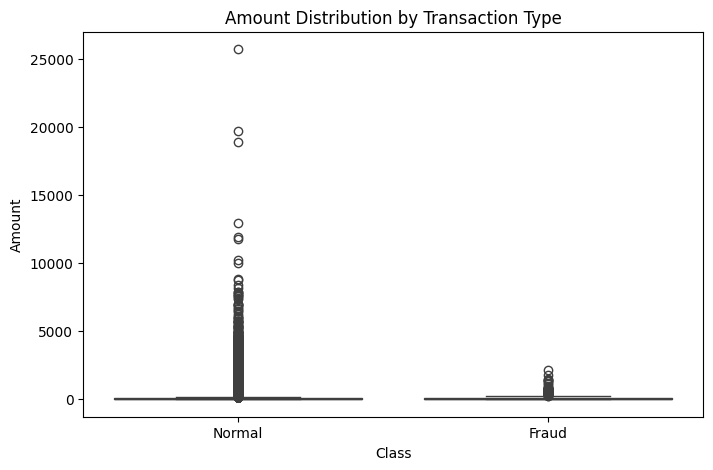

Class
0     88.291022
1    122.211321
Name: Amount, dtype: float64


In [85]:
# Fraud vs Normal Amount Comparison
plt.figure(figsize=(8,5))

sns.boxplot(x='Class', y='Amount', data=df)

plt.xticks([0,1], ['Normal', 'Fraud'])
plt.title("Amount Distribution by Transaction Type")

plt.show()

print(df.groupby('Class')['Amount'].mean())


<Axes: >

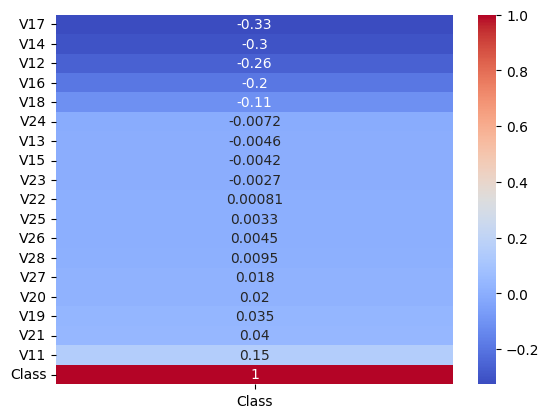

In [113]:
corr = df[[f'V{i}' for i in range(11, 29)] + ['Class']].corr()

sns.heatmap(corr[['Class']].sort_values(by='Class'),
            annot=True,
            cmap='coolwarm')

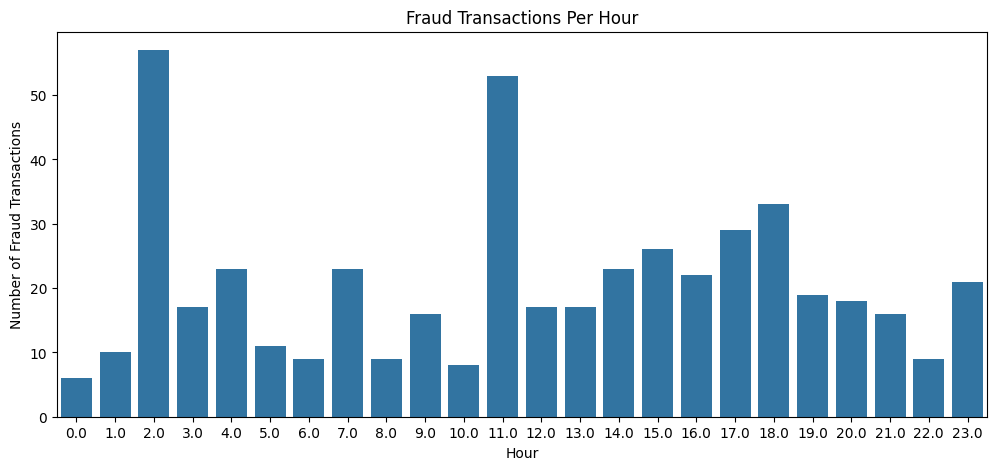

In [86]:
# Time Analysis

df['Hour'] = (df['Time'] // 3600) % 24 # Convert seconds to hours
fraud_by_hour = df[df['Class'] == 1]['Hour'].value_counts().sort_index() # Fraud transactions only

plt.figure(figsize=(12,5))

sns.barplot(
    x=fraud_by_hour.index,
    y=fraud_by_hour.values
)

plt.title("Fraud Transactions Per Hour")
plt.xlabel("Hour")
plt.ylabel("Number of Fraud Transactions")

plt.show()


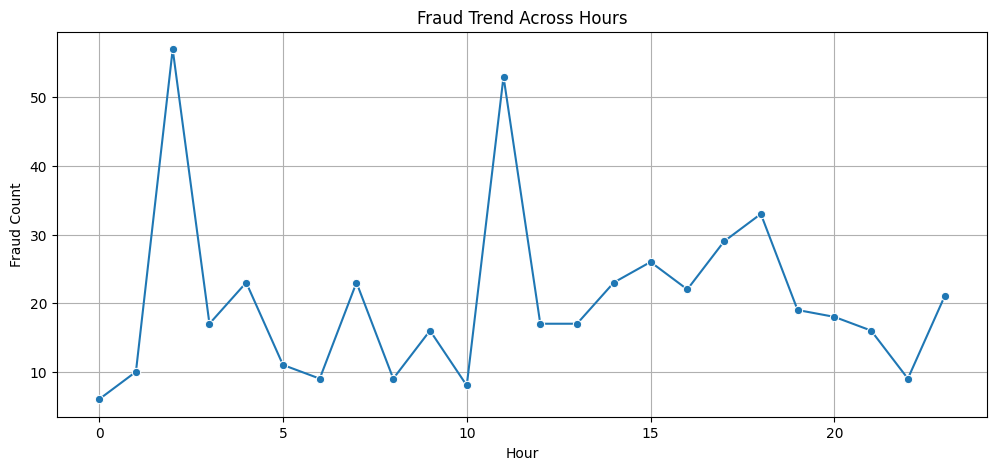

In [87]:
plt.figure(figsize=(12,5))

sns.lineplot(
    x=fraud_by_hour.index,
    y=fraud_by_hour.values,
    marker='o'
)

plt.title("Fraud Trend Across Hours")
plt.xlabel("Hour")
plt.ylabel("Fraud Count")

plt.grid(True)

plt.show()

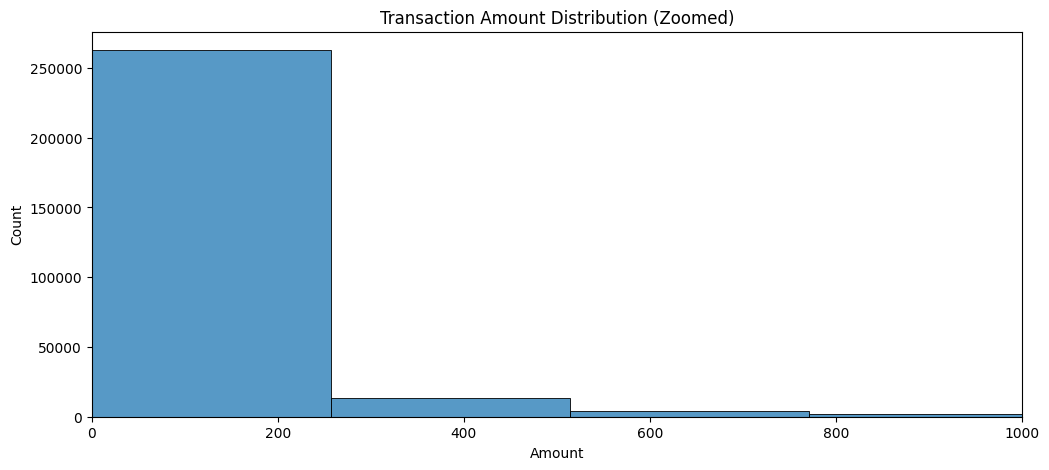

In [88]:
plt.figure(figsize=(12,5))

sns.histplot(df['Amount'], bins=100)

plt.xlim(0, 1000)

plt.title("Transaction Amount Distribution (Zoomed)")
plt.xlabel("Amount")
plt.ylabel("Count")

plt.show()

# Data Preprocessing

## Feature Scaling

In [89]:
scaler = StandardScaler()

df['scaled_amount'] = scaler.fit_transform(df['Amount'].values.reshape(-1,1))
df['scaled_time'] = scaler.fit_transform(df['Time'].values.reshape(-1,1))

## Feature Engineering

In [90]:
df['log_amount'] = np.log1p(df['Amount'])  # Log transform to reduce skewness in Amount
df['Hour'] = (df['Time'] // 3600) % 24  # Extract hour from Time (seconds → hour of day)
df['is_night'] = df['Hour'].apply(lambda x: 1 if x <= 6 else 0)  # Flag transactions occurring at night (0–6 AM)
df['high_amount'] = (df['Amount'] > df['Amount'].quantile(0.95)).astype(int)  # Flag top 5% high-value transactions
df['amount_per_hour'] = df['Amount'] / (df['Hour'] + 1)  # Interaction feature between amount and time context

In [91]:
df.drop(['Amount', 'Time'], axis=1, inplace=True)

## Train / Test Split

In [92]:
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Handling Imbalance

In [93]:
sm = SMOTE(random_state=42)

X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

# Model Training

In [94]:
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb.fit(X_train_res, y_train_res)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [22:39:24] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [95]:
y_proba_xgb = xgb.predict_proba(X_test)[:,1]
y_pred_xgb = (y_proba_xgb > 0.3)

In [96]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

rf = RandomForestClassifier(
    n_estimators=80, 
    max_depth=None,
    random_state=42,
    n_jobs=-1,           
    class_weight='balanced' 
)


rf.fit(X_train_res, y_train_res)


y_proba_rf = rf.predict_proba(X_test)[:,1]
y_pred_rf = (y_proba > 0.3)


# Model Evaluation

## XGBoost Evaluation

In [97]:
print("* XGBoostt Results *")
print(confusion_matrix(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_xgb))

* XGBoostt Results *
[[56826    38]
 [   12    86]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.69      0.88      0.77        98

    accuracy                           1.00     56962
   macro avg       0.85      0.94      0.89     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.9812953283451816


## Random Forest Evaluation 

In [98]:
print("* Random Forest Results *")
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_rf))

* Random Forest Results *
[[56826    38]
 [   12    86]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.69      0.88      0.77        98

    accuracy                           1.00     56962
   macro avg       0.85      0.94      0.89     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.9687170714515407


In [99]:
import joblib

joblib.dump(xgb, "/kaggle/working/xgboost.pkl")
joblib.dump(rf, "/kaggle/working/random_forest.pkl")

['/kaggle/working/random_forest.pkl']